In [1]:
import numpy as np
from scipy.linalg import eig
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from Unifac import Unifac
from sklearn.metrics import root_mean_squared_error
from UnifacDortmund import UnifacDortmund
from PhaseCalculation import CalculateComps as cc


tie_lines = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx", engine="calamine")
group_contribution = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\group_contribution.xlsx", engine="calamine")
comps_MW = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx", engine="calamine")

tie_lines = tie_lines.with_columns(
        pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref")
    ).with_row_index()

tie_lines = tie_lines.drop(["Type Alcohol"])
tie_lines_train = tie_lines.sample(fraction=0.8, with_replacement=False, seed=42).sort("index")
tie_lines_validate = tie_lines.filter(~tie_lines["index"].is_in(tie_lines_train["index"]))
tie_lines_train = tie_lines_train.drop(["index"])
tie_lines_validate = tie_lines_validate.drop(["index"])

group_contribution = group_contribution.drop(["MAG/DAG Profile?", "Additional FAME Profile?", "Acid mix Profile?", "Type Alcohol"])
comps_MW = comps_MW.drop(["Type Alcohol"])
tie_lines = tie_lines.drop(["index"])
group_tie_lines = tie_lines.group_by(["Ref", "Sub Ref", "Temperature (K)"], maintain_order=True)     

tie_lines_eval = tie_lines.select(['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H'])
tie_lines_eval_np = tie_lines_eval.to_numpy()    
thermo_model = UnifacDortmund


In [2]:
def compute_analysis(params):

    A = params[0:30]
    B = params[30:60]
    C = params[60:90]
    
    GIP = cc.define_GIP(A, B, C)
    
    results_list = []
    for name, data in group_tie_lines:
        tie_lines_np = data.drop(["Ref", "Sub Ref", "Temperature (K)"]).to_numpy()
        v = group_contribution.filter((pl.col("Ref") == name[0]) & (pl.col("Sub Ref") == name[1])).drop(["Ref", "Sub Ref"]).to_numpy()
        experiment_MW = comps_MW.filter((pl.col("Ref") == name[0]) & (pl.col("Sub Ref") == name[1])).drop(["Ref", "Sub Ref"]).to_numpy()
        experiment_MW.reshape(8) 
        results_list.append(cc.calculate_comps(tie_lines_np[:,0:8], v, experiment_MW, name[2], thermo_model, GIP, initial_guess=tie_lines_np[:,8:25])) #tie_lines_np[:,8:25]
    
    results_total = np.vstack(results_list) 
    mask = tie_lines_eval_np == 0
    results_total[mask] = 0 
    
    RMSE = root_mean_squared_error(tie_lines_eval_np, results_total)
    
    residuals = (tie_lines_eval_np - results_total) 

    variance = np.mean(residuals)**2/(tie_lines_eval_np.shape[0] - 90)
 
    return results_total, RMSE, variance, residuals
            
    

In [3]:
params = np.loadtxt(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\UDortmundParamsGARun1.out")

In [4]:
predictions, RMSE, variance, residuals = compute_analysis(params=params)

c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


In [27]:
stacked_real = np.vstack((tie_lines_eval_np[:,0:8], tie_lines_eval_np[:,8:16]))
stacked_ytotal = np.vstack((predictions[:,0:8], predictions[:,8:16]))
residuals = stacked_real - stacked_ytotal

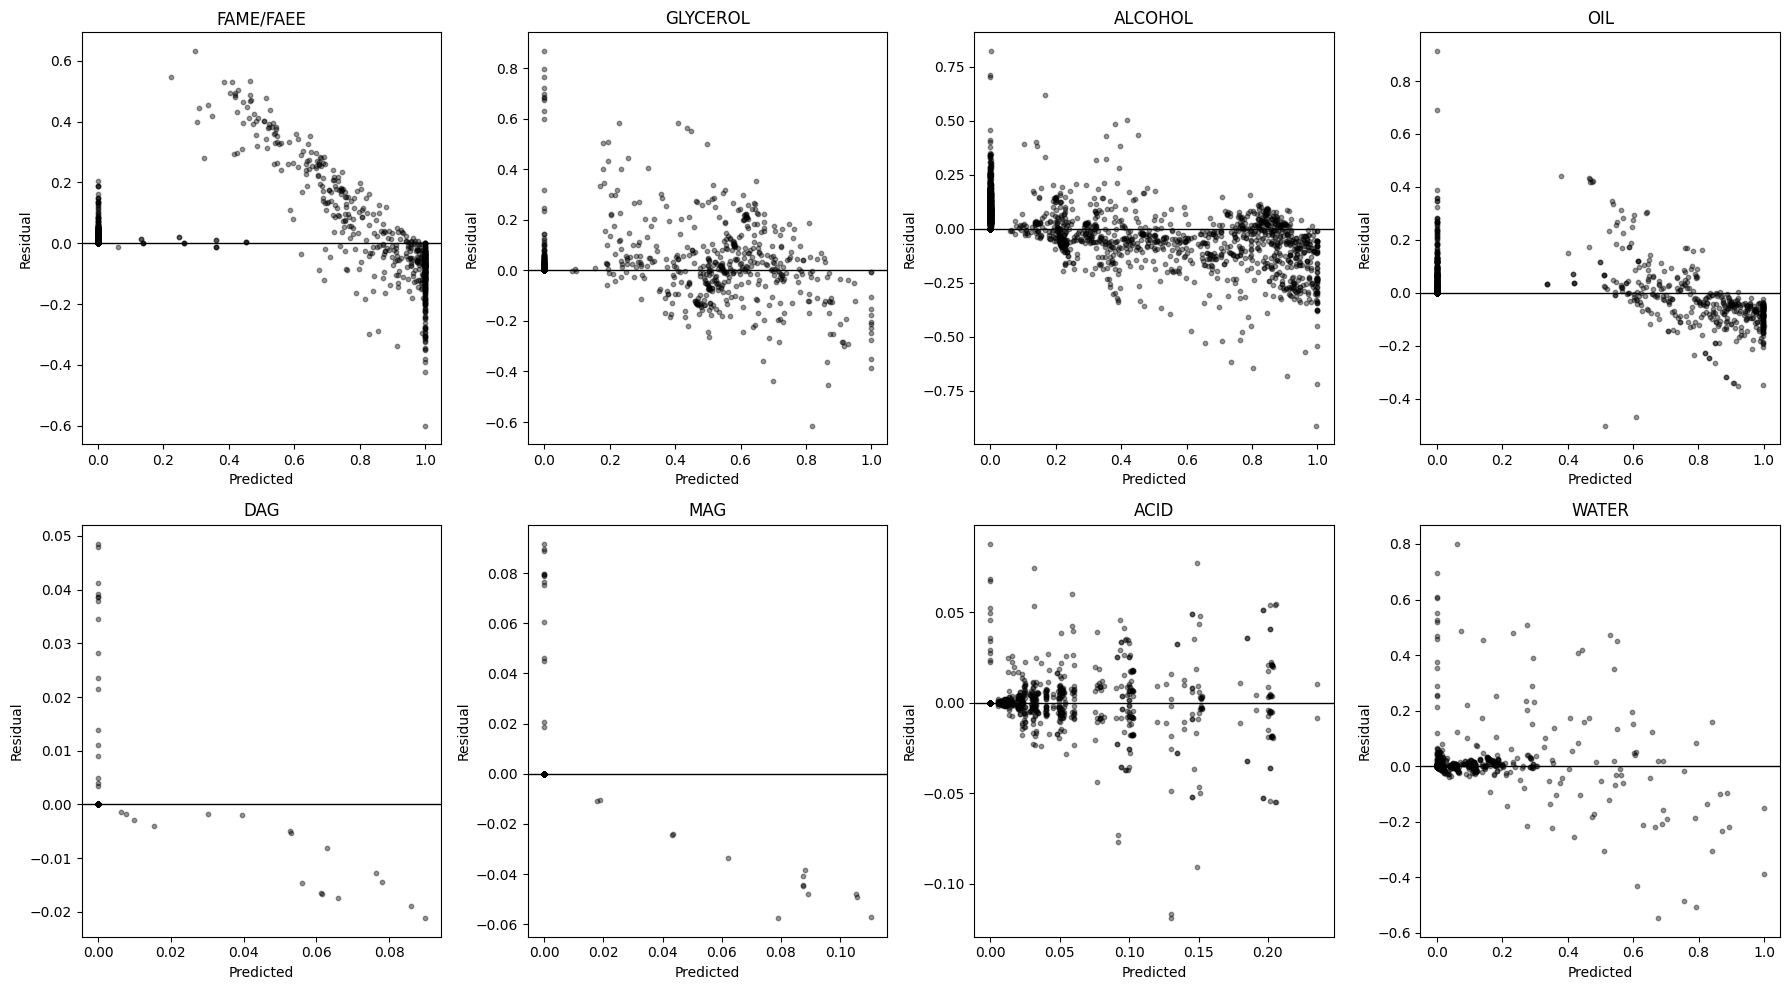

In [28]:
component_names = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.ravel()

for j in range(8):
    axes[j].scatter(stacked_ytotal[:, j], residuals[:, j], alpha=0.4, s=10, color="black")
    axes[j].axhline(0, color="k", lw=1)
    axes[j].set_title(component_names[j])
    axes[j].set_xlabel("Predicted")
    axes[j].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [6]:
J_full = np.zeros((tie_lines_eval_np.shape[0]*16, 90))
params_adjusted_plus = params.copy()
params_adjusted_minus = params.copy()

for i in range(57, 90, 1):
   print(i)
   step = params[i]*0.01
   params_adjusted_plus[i] = params_adjusted_plus[i] + step
   params_adjusted_minus[i] = params_adjusted_minus[i] - step
   results_total_plus, _, _, _= compute_analysis(params=params_adjusted_plus) 
   results_total_minus, _, _, _= compute_analysis(params=params_adjusted_minus)
   J_column = (results_total_plus - results_total_minus)/2*step 
   J_column = J_column.reshape(1027*16,)
   J_full[:,i] = J_column
  
   params_adjusted_plus[i] = params[i]
   params_adjusted_minus[i] = params[i]  
   
   
   with open('jacobian_1%_second_part.npy', 'wb') as f:
    np.save(f, J_full)
  

57


c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


58


c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


59


...

c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


88


c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


89


c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


Paró en 57

In [8]:
with open('jacobian.npy', 'rb') as f:
        jacobian_small = np.load(f)

with open('jacobian_1e-3.npy', 'rb') as f:
        jacobian_big = np.load(f)
 
with open('jacobian_1%.npy', 'rb') as f:
        jacobian_bigger_1 = np.load(f)
 
with open('jacobian_1%_second_part.npy', 'rb') as f:
        jacobian_bigger_2 = np.load(f)
       

In [22]:
col_norms = np.linalg.norm(jacobian_small, axis=0)
zero_params = np.where(col_norms < 1e-12)[0]
print(f"Parameters with zero sensitivity: {zero_params}")

Parameters with zero sensitivity: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 35 36 37 38 39 40 41 42 43 44 45 46 47 49
 50 51 52 53 54 55 56 57 58 59 60 61 62 63 65 66 67 68 69 70 71 72 73 74
 75 76 77 79 80 81 82 83 84 85 86 87 88 89]


In [36]:
col_norms = np.linalg.norm(jacobian_big, axis=0)
zero_params = np.where(col_norms < 1e-12)[0]
print(f"Parameters with zero sensitivity: {zero_params}")

Parameters with zero sensitivity: [ 0  3  5  6  8  9 10 11 12 13 14 15 17 19 20 21 22 23 24 25 26 27 28 29
 30 33 35 36 38 39 40 41 42 43 44 45 47 49 50 52 53 54 55 56 57 58 59 60
 63 65 66 68 69 70 71 72 73 74 75 77 79 80 82 83 84 85 86 87 88 89]


In [37]:
cov_small = variance*np.linalg.pinv(jacobian_small.T@jacobian_small)
std_errors = np.sqrt(np.diag(cov_small))
z_score = 1.96  # For 95% confidence interval
margin_of_error_small = z_score * std_errors

C:\Users\USER\AppData\Local\Temp\ipykernel_5532\4121208751.py:2: RuntimeWarning: invalid value encountered in sqrt
  std_errors = np.sqrt(np.diag(cov_small))


In [38]:
cov_big = variance*np.linalg.pinv(jacobian_big.T@jacobian_big)
std_errors = np.sqrt(np.diag(cov_big))
z_score = 1.96  # For 95% confidence interval
margin_of_error_big = z_score * std_errors

C:\Users\USER\AppData\Local\Temp\ipykernel_5532\504399045.py:2: RuntimeWarning: invalid value encountered in sqrt
  std_errors = np.sqrt(np.diag(cov_big))


In [40]:
std_errors

array([0.00000000e+00, 1.45526673e+06, 2.51902849e+06,            nan,
       1.16442510e+06,            nan, 6.94038575e-10, 1.21917226e+06,
       2.85316692e-10,            nan, 8.28430787e-10,            nan,
                  nan, 7.29225608e-10,            nan, 9.01735748e-10,
       1.58278216e+06, 0.00000000e+00, 1.10067113e+06, 0.00000000e+00,
       0.00000000e+00, 2.97008728e+03, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.36141268e+06,
       2.51645607e+06, 0.00000000e+00, 1.39685278e+06, 0.00000000e+00,
       0.00000000e+00, 1.15666806e+06, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 1.32007595e+06, 0.00000000e+00,
       1.39700307e+06, 0.00000000e+00, 0.00000000e+00, 1.85384675e+03,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [26]:
margin_of_error_big

array([0.00000000e+00, 2.85232279e+06, 4.93729585e+06,            nan,
       2.28227320e+06,            nan, 1.36031561e-09, 2.38957762e+06,
       5.59220716e-10,            nan, 1.62372434e-09,            nan,
                  nan, 1.42928219e-09,            nan, 1.76740207e-09,
       3.10225304e+06, 0.00000000e+00, 2.15731541e+06, 0.00000000e+00,
       0.00000000e+00, 5.82137107e+03, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.66836886e+06,
       4.93225389e+06, 0.00000000e+00, 2.73783145e+06, 0.00000000e+00,
       0.00000000e+00, 2.26706939e+06, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 2.58734887e+06, 0.00000000e+00,
       2.73812602e+06, 0.00000000e+00, 0.00000000e+00, 3.63353964e+03,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [33]:
non_zero_indices = np.where(std_errors > 0)[0]
active_parameters = params[non_zero_indices]

In [34]:
active_parameters

array([ 1.33233297, -0.80960185,  1.74643005,  1.62629307,  0.37206986,
        1.58280228, -0.58795406,  1.74953739, -1.89762826,  1.41453683,
       -1.27118576,  1.17624372,  0.53274644, -0.16031113,  1.7773432 ,
       -0.017355  ,  0.37290847,  1.09940532,  0.09460628, -1.13718672,
       -1.84722077, -0.38803571, -1.33169887, -0.29960547, -0.39216878,
       -1.44823156])

Active params:

a:
* (CH, CH2, CH3) - OH: 1.3323
* (CH, CH2, CH3) - CH2COO: -0.8096
* (CH, CH2. CH3) - H2O: 1.7464
* CH=CH - (CH, CH2, CH3): -1.137
* CH=CH - OH: -0.5880
* CH=CH - H2O: 1.7495
* OH - (CH, CH2, CH3): 1.6263
* OH - COOH: -1.8976
* OH - H2O: 1.4145
* CH2COO - H2O: -1.2712
* CH2COO - CH=CH: 1.1762
* CH2COO - (CH, CH2, CH3): 0.3721
* COOH - (CH, CH2, CH3): 1.5828

b:
* (CH, CH2, CH3) - OH: 0.5327
* (CH, CH2, CH3) - CH2COO: -0.1603
* (CH, CH2, CH3) - H2O: 1.7773
* OH - H2O: 0.3729
* CH2COO - (CH, CH2, CH3): -0.0174
* CH2COO - H2O: 1.0994
* CH2COO - CH=CH: 0.0946

c: 
* (CH, CH2, CH3) - COOH: 0.3700
* (CH, CH2, CH3) - H2O: -0.3880
* OH - H2O: -0.2996
* CH2COO - (CH, CH2, CH3): -1.3317
* CH2COO - CH=CH: -1.4482
* CH2COO - H2O: -0.3921

Total de 26/90 = 29%


In [16]:
jacobian_bigger_1[:,57:90] = jacobian_bigger_2[:,57:90] 

In [35]:
with open('jacobian_1%.npy', 'wb') as f:
    np.save(f, jacobian_bigger_1)


In [19]:
col_norms = np.linalg.norm(jacobian_bigger_1, axis=0)
zero_params = np.where(col_norms < 1e-12)[0]
print(f"Parameters with zero sensitivity: {zero_params}")

Parameters with zero sensitivity: [ 0  3  5  6  8  9 10 11 12 13 14 15 17 19 20 22 23 24 25 26 27 28 29 30
 32 33 35 36 38 39 40 41 42 43 44 45 47 49 50 52 53 54 55 56 57 58 59 60
 63 65 66 68 69 70 71 72 73 74 75 77 79 80 82 83 84 85 86 87 88 89]


In [20]:
cov_bigger = variance*np.linalg.pinv(jacobian_bigger_1.T@jacobian_bigger_1)
std_errors = np.sqrt(np.diag(cov_bigger))
z_score = 1.96  # For 95% confidence interval
margin_of_error_big = z_score * std_errors

C:\Users\USER\AppData\Local\Temp\ipykernel_5532\870716510.py:2: RuntimeWarning: invalid value encountered in sqrt
  std_errors = np.sqrt(np.diag(cov_bigger))


In [21]:
margin_of_error_big

array([0.00000000e+00, 1.39826031e+05, 2.92919897e+05,            nan,
       1.01897938e+05, 6.01183208e-06,            nan, 5.35621188e+05,
       4.36535822e-10, 3.14190252e-10, 6.95880218e-10,            nan,
                  nan,            nan,            nan, 0.00000000e+00,
       1.91824122e+05, 0.00000000e+00, 1.97812173e+05, 0.00000000e+00,
       0.00000000e+00, 2.91468387e+02, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 6.10468733e+05,
       6.65740357e-01, 0.00000000e+00, 7.67412027e+01, 0.00000000e+00,
       0.00000000e+00, 1.88017049e+04, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 6.56068716e+05, 0.00000000e+00,
       2.02616575e+02, 0.00000000e+00, 0.00000000e+00, 2.85286557e+01,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [34]:
J_full = np.zeros((tie_lines_eval_np.shape[0]*16, 90))
params_adjusted_plus = params.copy()
params_adjusted_minus = params.copy()

step = params[0]*1.1
print(step)
params_adjusted_plus[0] = params_adjusted_plus[0] + step
params_adjusted_minus[0] = params_adjusted_minus[0] - step

print(params_adjusted_plus, params_adjusted_minus)

results_total_plus, RMSE_1, _, _= compute_analysis(params=params_adjusted_plus) 
results_total_minus, RMSE_2, _, _= compute_analysis(params=params_adjusted_minus)

print(results_total_plus, results_total_minus)

print(RMSE_1, RMSE_2)

diff=results_total_plus-results_total_minus
print(diff) 
  
params_adjusted_plus[0] = params[0]
params_adjusted_minus[0] = params[0]


print(params_adjusted_plus,params_adjusted_minus)

-0.5734106613408905
[-1.09469308  1.33233297 -0.80960185 -0.45529374  1.74643005 -1.13710763
  1.62629307  0.37206986  1.58280228  1.41648021 -0.58795406 -0.44014695
  1.87275794  1.74953739 -0.84597616 -1.89762826  1.41453683 -0.5432559
 -1.27118576  0.26952532 -1.65233506  1.17624372 -0.82328491  1.42465672
 -1.23784974  0.66402747 -1.1461843   1.86330465 -0.32114494 -1.40016613
 -1.62595621  0.53274644 -0.16031113  1.25130071  1.7773432  -0.36377721
 -1.84137912 -0.017355   -1.70240368  1.44349142 -0.70890076 -0.47510121
 -0.29388734  1.71014839  0.3230462  -0.75801276  0.37290847 -0.79101536
  1.09940532  0.62695973 -1.41376257  0.09460628  0.43828779 -0.62637103
 -1.22991917  0.190194    0.9515889  -1.09385244 -0.41154456 -0.30683273
  1.45796934 -1.13718672 -1.84722077  0.37003365 -0.38803571  0.91101555
  0.60469041 -1.33169887  1.90678314  0.57990339 -0.85161842 -0.74622437
 -0.1946477  -0.1359282   1.73960736 -0.61892398 -0.29960547 -1.89695163
 -0.39216878  0.89027727 -1.0585

c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)
c:\Juan\Maestría\Code\oleosim\PhaseCalculation\predict_comps.py:156: RuntimeWarning: overflow encountered in divide
  Ki = np.clip(gamma_light / gamma_heavy, 1e-6, 1e6)


[[9.99000000e-01 6.63088979e-07 1.66439386e-06 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.63124736e-01 6.41388238e-07 1.84214484e-05 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.99000000e-01 6.81657114e-07 2.71387846e-06 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 0.00000000e+00 1.06298999e-06 ... 0.00000000e+00
  0.00000000e+00 4.02413336e-02]
 [0.00000000e+00 0.00000000e+00 9.04807599e-07 ... 0.00000000e+00
  0.00000000e+00 5.72233667e-02]
 [0.00000000e+00 0.00000000e+00 9.18525771e-07 ... 0.00000000e+00
  0.00000000e+00 8.10251592e-02]] [[9.99000000e-01 6.63088979e-07 1.66439386e-06 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.63124736e-01 6.41388238e-07 1.84214484e-05 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.99000000e-01 6.81657114e-07 2.71387846e-06 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 0.00000000e+00 1.06298999e-06 ... 0.00000000e+00
  0.00000000e+00 4.02413336e-02]